In [3]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

xr.set_options(use_bottleneck=False); # Accurate float32 reduction

DATADIR = Path("../data/lite")

# File handling
FILES = {
    "hist_1": "hist_train_1850_1931",
    "hist_2": "hist_train_1932_2014",
    "ssp126": "train_ssp126",
    "ssp370": "train_ssp370",
    "ssp585": "train_ssp585",
    "forcings_all": "forcings_all"
}

def open_file(key):
    """Open the ClimX file whose name ends with the suffix for `key`."""
    path = next(DATADIR.glob(f"*{FILES[key]}.nc"))
    return xr.open_dataset(path)

# Area weighted global mean
def global_mean(da):
    """Average over lat and lon, weighting each cell by
    cos(latitude)."""
    weights = np.cos(np.deg2rad(da.lat))
    return da.weighted(weights).mean(dim=("lat", "lon"))

# Data parameters
GHG = ["CO2_LBC", "CH4_LBC", "N2O_LBC", "CFC11eq_LBC", "CF2CL2_LBC"]
AEROSOLS = ["BC_AX", "BC_N", "SO2", "SO4_PR", "OM_NI"]
TRAIN = ["ssp126", "ssp370", "ssp585"]
TEST = "ssp245"

# Style parameters
COLORS = {"historical": "#555555", "ssp126": "#2a78d6", "ssp245": "#eda100",
          "ssp370": "#eb6834", "ssp585": "#1baf7a"}
STYLES = {s: "-" for s in COLORS} | {"ssp245": "--"}   # test scenario dashed

In [10]:
with open_file("forcings_all") as ds:
    fa = ds[GHG + AEROSOLS].sel(forcing_scenario='ssp126')
print(fa.forcing_scenario)

<xarray.DataArray 'forcing_scenario' ()> Size: 24B
array('ssp126', dtype='<U6')
Coordinates:
    forcing_scenario  <U6 24B 'ssp126'


In [ ]:
# Historical forcing data (1850-2014)
with open_file("hist_2") as ds:
    hist2 = ds[GHG + AEROSOLS].isel(forcing_scenario=0).load()
print(hist2)

#### Check if two historical datasets contain the same forcing variable data

In [16]:
FORCINGS = GHG + AEROSOLS

with open_file("hist_1") as ds:
      h1 = ds[FORCINGS].load()

with open_file("hist_2") as ds:
    h2 = ds[FORCINGS].load()

In [17]:
for c in ["time_year", "time_month", "lat", "lon"]:
    same = h1[c].size == h2[c].size and bool((h1[c].values == h2[c].values).all())
    print(f"{c:10s}: hist_1 {h1[c].values[0]} … {h1[c].values[-1]} ({h1[c].size}) | "
          f"hist_2 {h2[c].values[0]} … {h2[c].values[-1]} ({h2[c].size}) | identical: {same}")

time_year : hist_1 1850-07-02 12:00:00 … 2014-07-02 12:00:00 (165) | hist_2 1850-07-02 12:00:00 … 2014-07-02 12:00:00 (165) | identical: True
time_month: hist_1 1850-01-17 00:00:00 … 2014-12-18 00:00:00 (1980) | hist_2 1850-01-17 00:00:00 … 2014-12-18 00:00:00 (1980) | identical: True
lat       : hist_1 -82.93193717277487 … 82.93193717277487 (12) | hist_2 -82.93193717277487 … 82.93193717277487 (12) | identical: True
lon       : hist_1 9.375 … 349.375 (18) | hist_2 9.375 … 349.375 (18) | identical: True


In [20]:
print("equals   :", h1.equals(h2))      # same values and coordinates
print("identical:", h1.identical(h2))   # same values, coordinates AND attributes

equals   : True
identical: True


In [51]:
# Load the forcing data for future and historical scenarios
with open_file("forcings_all") as ds:
    fa = ds[GHG + AEROSOLS].load()

with open_file("hist_2") as ds:
    hist = ds[GHG + AEROSOLS].isel(forcing_scenario=0).load()

print(fa.forcing_scenario.values)

['ssp126' 'ssp245' 'ssp370' 'ssp585']


In [65]:
# Helper to turns any forcing into yearly values
def to_yearly(da: xr.DataArray) -> xr.DataArray:
    """
    GHGs: relabel the yearly axis as integer years.
    Aerosols: average the monthly values to annual means.
    """
    if "time_year" in da.dims:
        return (da.assign_coords(year=da.time_year.dt.year)
                .swap_dims(time_year="year")
                .drop_vars("time_year"))
    return da.groupby("time_month.year").mean()

In [80]:
to_yearly(fa["CO2_LBC"].sel(forcing_scenario="ssp126")).year.values[[0, -1]]

array([2015, 2100])

In [82]:
to_yearly(global_mean(hist["SO2"])).dims

('year',)

#### Greenhouse-gas trajectories

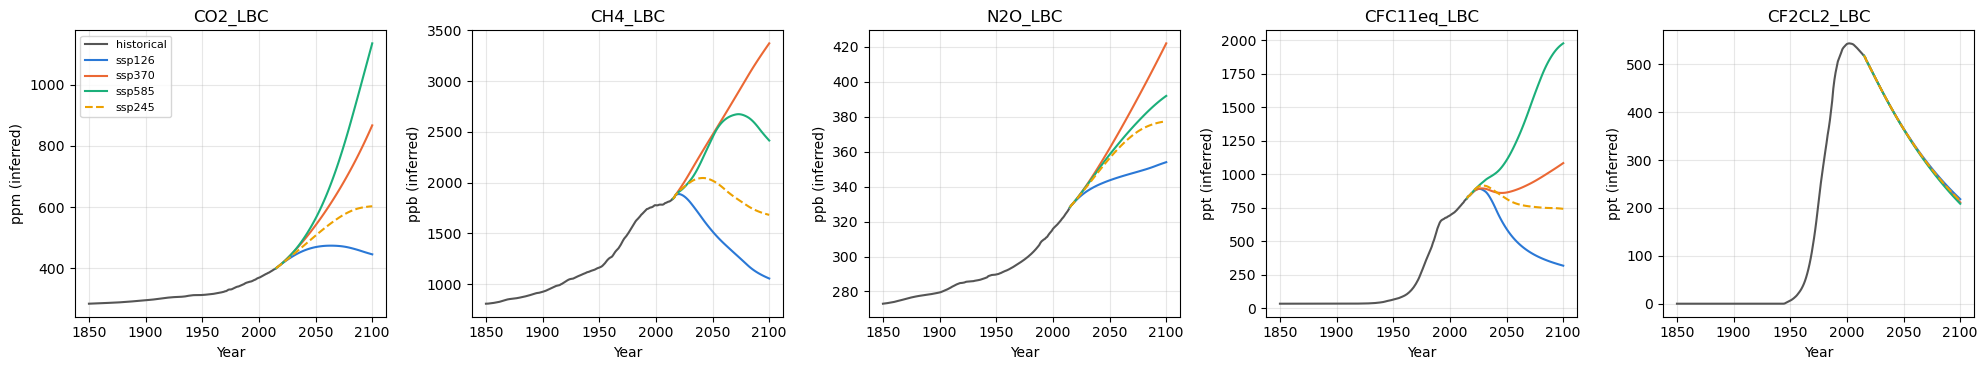

In [83]:
GHG_UNITS = {"CO2_LBC": (1e6, "ppm"), "CH4_LBC": (1e9, "ppb"), "N2O_LBC":(1e9, "ppb"),
             "CFC11eq_LBC": (1e12, "ppt"), "CF2CL2_LBC": (1e12, "ppt")}

fig, axes = plt.subplots(1, len(GHG), figsize=(20, 3.8))
for ax, v in zip(axes, GHG):
    scale, unit = GHG_UNITS[v]
    h = to_yearly(hist[v])
    ax.plot(h.year, h * scale, color=COLORS["historical"], label="historical")
    for s in TRAIN + [TEST]:
        y = to_yearly(fa[v].sel(forcing_scenario=s))
        ax.plot(y.year, y * scale, color=COLORS[s], linestyle=STYLES[s], label=s)
    ax.set_title(v)
    ax.set_xlabel("Year")
    ax.set_ylabel(f"{unit} (inferred)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Aerosol trajectories (global mean)

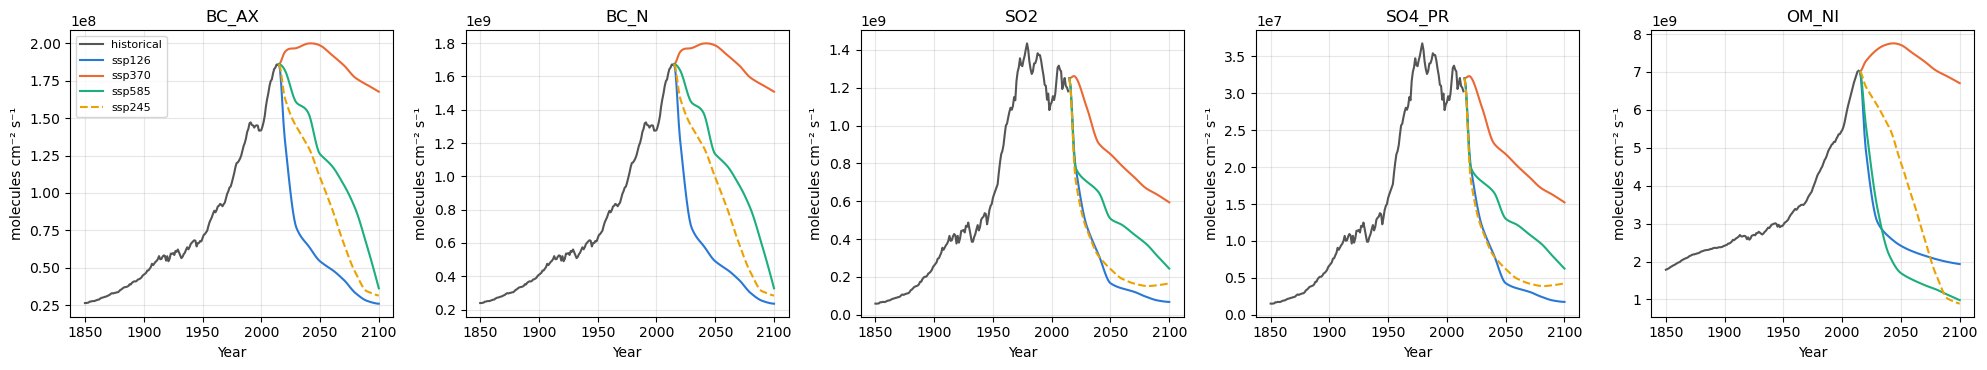

In [84]:
fig, axes = plt.subplots(1, len(AEROSOLS), figsize=(20, 3.8))
for ax, v in zip(axes, AEROSOLS):
    h = to_yearly(global_mean(hist[v]))
    ax.plot(h.year, h, color=COLORS["historical"], label="historical")
    for s in TRAIN + [TEST]:
        y = to_yearly(global_mean(fa[v].sel(forcing_scenario=s)))
        ax.plot(y.year, y, color=COLORS[s], linestyle=STYLES[s], label=s)
    ax.set_title(v)
    ax.set_xlabel("Year")
    ax.set_ylabel("molecules cm⁻² s⁻¹")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()